# China’s Solar PV Exports: Data Cleaning and Preliminary Analysis
This notebook examines monthly Chinese solar panel exports from 2022 to 2025. It includes reproducible cleaning, a data dictionary, a data quality audit, exploratory figures, annual growth rates, and processed-data exports.

**Main research question:** Which destination markets, product categories, and sales periods should Chinese solar PV exporters prioritize to improve expected commercial returns?

This stage focuses on Panels. It describes market scale and export patterns; it does not estimate profits or complete the final commercial-feasibility analysis.



## 1. Upload and import the data
Upload `mart_solar_exports_full_release_monthly.csv`. The dataframe `df` contains the original imported data. Keep it unchanged for comparison with the filtered sample.

Source: [Ember China Solar Export dataset](https://ember-energy.org/data/china-solar-exports-data/).
[CSV download](https://files.ember-energy.org/public-downloads/customs/outputs/mart_solar_exports_full_release_monthly.csv).
[Methodology v4](https://files.ember-energy.org/public-downloads/ember_china_solar_exports_methodology_v4.pdf).
The raw CSV is updated over time, so preserve the uploaded snapshot.

In [1]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))
df.head()

Saving mart_solar_exports_full_release_monthly.csv to mart_solar_exports_full_release_monthly.csv


,Area,Date,Area type,Region,Commodity code,Commodity type,Amount (items),Amount (kg),Amount (USD),Commodity price,Price unit,Capacity (MW),Cumulative capacity (MW)
0,Afghanistan,2017-01-01,Country or economy,Asia,85414020,Panels,49433,333324.0,1663024.0,0.38,USD/W,4.38,4.38
1,Afghanistan,2017-02-01,Country or economy,Asia,85414020,Panels,5452,82456.0,337723.0,0.38,USD/W,0.89,5.27
2,Afghanistan,2017-03-01,Country or economy,Asia,85414020,Panels,51403,940507.0,3477201.0,0.38,USD/W,9.15,14.42
3,Afghanistan,2017-04-01,Country or economy,Asia,85414020,Panels,100875,1306053.0,4783758.0,0.38,USD/W,12.59,27.00
4,Afghanistan,2017-05-01,Country or economy,Asia,85414020,Panels,67325,786843.0,2823671.0,0.38,USD/W,7.43,34.44


## 2. Select the analysis sample
We retain Panels, 2022–2025, and country/economy records. Geographic aggregates such as World, Europe and EU are excluded because combining them with country rows would double count exports.

Each row in the filtered dataset represents **one destination country/economy × one reporting month × Panels**. Starting in 2022 provides a consistent panel commodity code, 85414300.

In [2]:
data = df.copy()
data["Date"] = pd.to_datetime(data["Date"])

panel_rows = data[data["Commodity type"] == "Panels"].copy()
period_rows = panel_rows[panel_rows["Date"].dt.year.between(2022, 2025)].copy()
panels = period_rows[period_rows["Area type"] == "Country or economy"].copy()
panels = panels.sort_values(["Area", "Date"]).reset_index(drop=True)

row_counts = pd.DataFrame({
    "Step": ["Original data", "Panels only", "2022–2025", "Country/economy only"],
    "Rows": [len(df), len(panel_rows), len(period_rows), len(panels)]
})
display(row_counts)
display(panels.head())

,Step,Rows
0,Original data,31624
1,Panels only,21844
2,2022–2025,9434
3,Country/economy only,8810


,Area,Date,Area type,Region,Commodity code,Commodity type,Amount (items),Amount (kg),Amount (USD),Commodity price,Price unit,Capacity (MW),Cumulative capacity (MW)
0,Afghanistan,2022-01-01,Country or economy,Asia,85414300,Panels,24939,460277.0,1189987.0,0.26,USD/W,4.54,297.20
1,Afghanistan,2022-02-01,Country or economy,Asia,85414300,Panels,10305,182467.0,512588.0,0.26,USD/W,2.01,299.20
2,Afghanistan,2022-03-01,Country or economy,Asia,85414300,Panels,17482,340358.0,1129189.0,0.25,USD/W,4.57,303.77
3,Afghanistan,2022-04-01,Country or economy,Asia,85414300,Panels,10647,206282.0,619218.0,0.28,USD/W,2.21,305.99
4,Afghanistan,2022-05-01,Country or economy,Asia,85414300,Panels,14827,293796.0,1149093.0,0.29,USD/W,4.01,309.99


## 3. Data quality audit
### 3.1 Coverage
Report the date range, number of destinations, number of reporting months, and coverage by year. All counts below are calculated from the uploaded file.

In [3]:
print("Original shape:", df.shape)
print("Original date range:", data["Date"].min(), "to", data["Date"].max())
print("Selected rows:", len(panels))
print("Selected destinations:", panels["Area"].nunique())
print("Selected months:", panels["Date"].nunique())
print("Selected date range:", panels["Date"].min(), "to", panels["Date"].max())

coverage_by_year = panels.groupby(panels["Date"].dt.year).agg(
    rows=("Area", "size"),
    destinations=("Area", "nunique"),
    months=("Date", "nunique")
)
coverage_by_year

Original shape: (31624, 13)
Original date range: 2017-01-01 00:00:00 to 2026-09-01 00:00:00
Selected rows: 8810
Selected destinations: 228
Selected months: 48
Selected date range: 2022-01-01 00:00:00 to 2025-12-01 00:00:00


,rows,destinations,months
Date,,,
2022,2066,210,12
2023,2182,221,12
2024,2246,213,12
2025,2316,218,12


### 3.2 Missing values
Check explicit missing cells in the original file and the selected sample. Missing cells differ from entirely absent destination-month records; the latter are checked separately below.

In [4]:
missing_values = pd.DataFrame({
    "Original missing": df.isna().sum(),
    "Selected missing": panels.isna().sum(),
    "Selected missing (%)": panels.isna().mean() * 100
})
display(missing_values)

print("Area types associated with missing Region values:")
display(df.loc[df["Region"].isna(), "Area type"].value_counts())

,Original missing,Selected missing,Selected missing (%)
Area,0,0,0.0
Date,0,0,0.0
Area type,0,0,0.0
Region,2900,0,0.0
Commodity code,0,0,0.0
Commodity type,0,0,0.0
Amount (items),0,0,0.0
Amount (kg),0,0,0.0
Amount (USD),0,0,0.0
Commodity price,0,0,0.0


Area types associated with missing Region values:


,count
Area type,
Region,2900


### 3.3 Duplicates
Check both completely identical rows and repeated destination-month-product keys. Duplicate checks are diagnostic: records are not silently dropped.

In [5]:
print("Original exact duplicates:", df.duplicated().sum())
print("Selected exact duplicates:", panels.duplicated().sum())
print("Selected duplicate destination-month-product keys:",
      panels.duplicated(["Area", "Date", "Commodity type"]).sum())

Original exact duplicates: 0
Selected exact duplicates: 0
Selected duplicate destination-month-product keys: 0


### 3.4 Implausible values and large observations
Check numeric types, negative values, non-finite values, zero values and the largest exports. Zero estimated capacity with positive value can arise from rounding of small shipments, but that explanation is not independently verified. Large exports are retained unless there is evidence of an error.

In [6]:
import numpy as np

numeric_columns = ["Amount (items)", "Amount (kg)", "Amount (USD)",
                   "Commodity price", "Capacity (MW)", "Cumulative capacity (MW)"]
panels[numeric_columns] = panels[numeric_columns].apply(pd.to_numeric)

numeric_audit = pd.DataFrame({
    "Missing": panels[numeric_columns].isna().sum(),
    "Non-finite": (~np.isfinite(panels[numeric_columns])).sum(),
    "Negative": (panels[numeric_columns] < 0).sum(),
    "Zero": (panels[numeric_columns] == 0).sum(),
    "Minimum": panels[numeric_columns].min(),
    "Maximum": panels[numeric_columns].max()
})
display(numeric_audit)
print("Commodity codes:", panels["Commodity code"].unique())
print("Price units:", panels["Price unit"].unique())

zero_capacity = panels[panels["Capacity (MW)"] == 0]
display(zero_capacity[["Area", "Date", "Amount (USD)", "Capacity (MW)"]].head())
display(panels.nlargest(10, "Amount (USD)")[["Area", "Date", "Amount (USD)", "Capacity (MW)"]])

,Missing,Non-finite,Negative,Zero,Minimum,Maximum
Amount (items),0,0,0,0,1.00,2.434277e+07
Amount (kg),0,0,0,0,1.00,2.863293e+08
Amount (USD),0,0,0,0,8.00,1.283227e+09
Commodity price,0,0,0,0,0.09,2.900000e-01
Capacity (MW),0,0,0,160,0.00,5.821200e+03
Cumulative capacity (MW),0,0,0,1,0.00,2.045899e+05


Commodity codes: [85414300]
Price units: ['USD/W']


,Area,Date,Amount (USD),Capacity (MW)
121,Algeria,2024-06-01,260.0,0.0
145,Andorra,2022-05-01,24.0,0.0
148,Angola,2022-02-01,480.0,0.0
210,Anguilla,2025-09-01,116.0,0.0
469,Azerbaijan,2022-04-01,576.0,0.0


,Area,Date,Amount (USD),Capacity (MW)
3506,India,2022-02-01,1.283227e+09,5027.62
5462,Netherlands,2023-03-01,1.278719e+09,5821.20
5464,Netherlands,2023-05-01,1.220429e+09,5612.37
5452,Netherlands,2022-05-01,1.201091e+09,4186.42
5453,Netherlands,2022-06-01,1.190565e+09,4150.77
5454,Netherlands,2022-07-01,1.189837e+09,4044.58
5455,Netherlands,2022-08-01,1.092872e+09,3711.92
5451,Netherlands,2022-04-01,1.064053e+09,3801.56
5463,Netherlands,2023-04-01,1.057412e+09,4783.80
5465,Netherlands,2023-06-01,1.048521e+09,4983.20


### 3.5 Missing destination-month combinations
The analysis window contains 48 months. Not every destination has a record in every month. The expected grid below uses destinations observed at least once during the window.

In [7]:
coverage = panels.groupby("Area")["Date"].nunique().reset_index(name="Observed months")
coverage["Absent months"] = 48 - coverage["Observed months"]

print("Destinations with all 48 months:", (coverage["Observed months"] == 48).sum())
print("Absent destination-month combinations:", coverage["Absent months"].sum())
display(coverage.sort_values("Observed months").head(15))

Destinations with all 48 months: 111
Absent destination-month combinations: 2134


,Area,Observed months,Absent months
108,Liechtenstein,1,47
126,Monaco,1,47
143,Niue,1,47
216,United States Minor Outlying Islands,1,47
144,North Korea,1,47
159,Pitcairn Islands,1,47
129,Montserrat,1,47
22,Bermuda,2,46
168,Saint Barthelemy,2,46
169,Saint Helena and Ascension and Tristan da Cunha,2,46


### 3.6 Audit findings and cleaning decisions



In [19]:
audit_text = f"""The original dataset contains {len(df):,} rows and {df.shape[1]} columns.
After filtering, the analysis contains {len(panels):,} records across {panels['Area'].nunique()} destinations
and {panels['Date'].nunique()} distinct months. The selected sample has
{int(panels.isna().sum().sum())} missing cells and
{int(panels.duplicated(['Area', 'Date', 'Commodity type']).sum())} duplicate destination-month-product keys.
The numeric audit identifies {int((panels[numeric_columns] < 0).sum().sum())} negative numeric cells.
There are {len(zero_capacity)} records with zero estimated capacity;
{int((zero_capacity['Amount (USD)'] > 0).sum())} of these have positive export value.

Only {int((coverage['Observed months'] == 48).sum())} destinations have all 48 months.
There are {int(coverage['Absent months'].sum()):,} absent destination-month combinations
relative to the observed-destination grid. Absence is not assumed to mean zero trade.
Missing cells and absent records are treated as separate coverage issues.

Cleaning converts dates and numeric types, filters the sample, and sorts observations.
No missing values are imputed, no duplicates are silently removed, and no outliers
are deleted because of their size. Geographic aggregate rows are excluded
to prevent double counting. No external joins are performed.
"""
print(audit_text)

The original dataset contains 31,624 rows and 13 columns.
After filtering, the analysis contains 8,810 records across 228 destinations
and 48 distinct months. The selected sample has
0 missing cells and
0 duplicate destination-month-product keys.
The numeric audit identifies 0 negative numeric cells.
There are 160 records with zero estimated capacity;
160 of these have positive export value.

Only 111 destinations have all 48 months.
There are 2,134 absent destination-month combinations
relative to the observed-destination grid. Absence is not assumed to mean zero trade.
Missing cells and absent records are treated as separate coverage issues.

Cleaning converts dates and numeric types, filters the sample, and sorts observations.
No missing values are imputed, no duplicates are silently removed, and no outliers
are deleted because of their size. Geographic aggregate rows are excluded
to prevent double counting. No external joins are performed.



## 4. Data dictionary
Source definitions follow Ember methodology v4 where available. Date encoding and geography labels describe the supplied CSV.

| Variable | Unit | Definition |
|---|---|---|
| Area | None | Recorded first destination country/economy; may differ from final consumption destination. |
| Date | YYYY-MM-DD | Reporting month, encoded as its first day. |
| Area type | None | Geographic row classification; only Country or economy is retained. |
| Region | None | Regional label supplied with the destination. |
| Commodity code | HS code | Customs product classification; panel code is 85414300 in this period. |
| Commodity type | None | Product category; this analysis retains Panels. |
| Amount (items) | Items | Customs-reported export quantity. |
| Amount (kg) | kg | Customs-reported export weight. |
| Amount (USD) | USD | Customs-reported export value; not profit. |
| Commodity price | USD/W for panels | Monthly reference price based on InfoLink and product-type weights; not a destination-specific transaction price. |
| Price unit | None | Unit of Commodity price; USD/W for this sample. |
| Capacity (MW) | MW | Ember estimate from export value / monthly reference price / 1,000,000 for panels; indicative rather than direct customs capacity. |
| Cumulative capacity (MW) | MW | Source cumulative field; exact accumulation convention is not specified in cited methodology. Retained for provenance and not aggregated. |
| year | Year | Calendar year extracted from Date. |
| month | 1–12 | Calendar month extracted from Date. |
| value_growth_pct | % | (Current annual Amount (USD) / prior annual Amount (USD) - 1) * 100. |
| capacity_growth_pct | % | (Current annual Capacity (MW) / prior annual Capacity (MW) - 1) * 100. |

**Output row units:** `panels_processed.csv`: one destination-month-panel record; `monthly_exports.csv`: one month summed over recorded destinations; `annual_exports.csv`: one calendar year. Amount and capacity columns in the monthly and annual files are sums of the corresponding country-month fields. The first year's growth rates are missing by design.

## 5. Preliminary exploratory analysis
### 5.1 Descriptive statistics
These statistics summarize the distribution of observed destination-month exports.

In [9]:
panels[["Amount (USD)", "Capacity (MW)", "Amount (kg)"]].describe()

,Amount (USD),Capacity (MW),Amount (kg)
count,8.810000e+03,8810.000000,8.810000e+03
mean,1.516111e+07,96.552370,5.066368e+06
std,6.310320e+07,342.663535,1.830256e+07
min,8.000000e+00,0.000000,1.000000e+00
25%,1.013350e+05,0.650000,2.894950e+04
50%,8.238570e+05,5.220000,2.490970e+05
75%,6.430244e+06,46.817500,2.323594e+06
max,1.283227e+09,5821.200000,2.863293e+08


### 5.2 Monthly export value and capacity


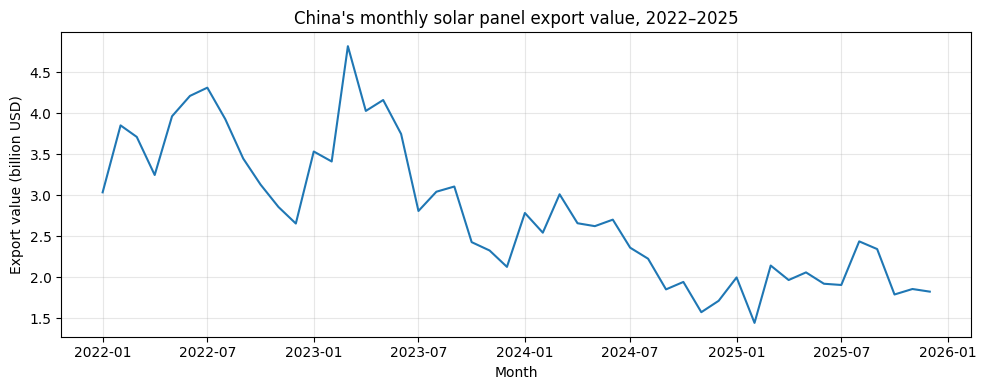

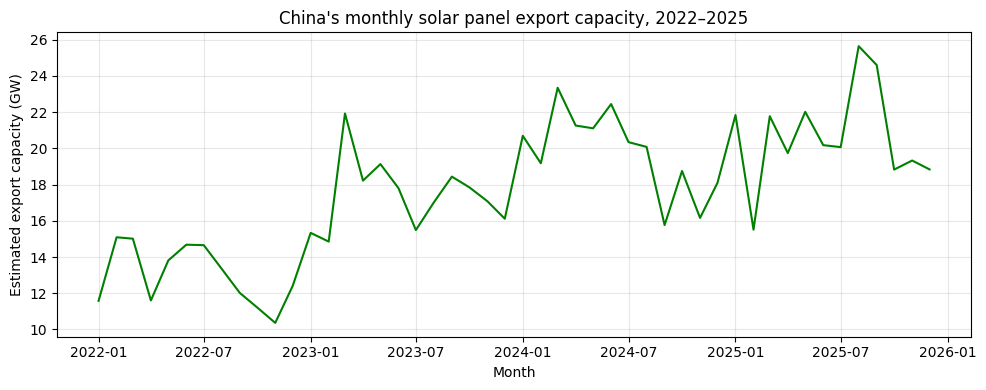

In [10]:
import matplotlib.pyplot as plt

monthly = panels.groupby("Date")[["Amount (USD)", "Capacity (MW)"]].sum()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly["Amount (USD)"] / 1e9)
plt.title("China's monthly solar panel export value, 2022–2025")
plt.xlabel("Month")
plt.ylabel("Export value (billion USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly["Capacity (MW)"] / 1000, color="green")
plt.title("China's monthly solar panel export capacity, 2022–2025")
plt.xlabel("Month")
plt.ylabel("Estimated export capacity (GW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 Annual exports and growth
Annual growth is calculated separately for export value and estimated capacity. The 2022 growth rate is left missing because 2022 is the baseline of the analysis window.

In [11]:
panels["year"] = panels["Date"].dt.year
panels["month"] = panels["Date"].dt.month

annual = panels.groupby("year")[["Amount (USD)", "Capacity (MW)"]].sum()
annual["value_growth_pct"] = annual["Amount (USD)"].pct_change(fill_method=None) * 100
annual["capacity_growth_pct"] = annual["Capacity (MW)"].pct_change(fill_method=None) * 100

annual_table = pd.DataFrame({
    "Value (billion USD)": annual["Amount (USD)"] / 1e9,
    "Capacity (GW)": annual["Capacity (MW)"] / 1000,
    "Value growth (%)": annual["value_growth_pct"],
    "Capacity growth (%)": annual["capacity_growth_pct"]
})
annual_table.round(2)

,Value (billion USD),Capacity (GW),Value growth (%),Capacity growth (%)
year,,,,
2022,42.35,155.76,NaN,NaN
2023,39.53,209.26,-6.64,34.35
2024,28.00,237.24,-29.19,13.37
2025,23.69,248.37,-15.36,4.69


### 5.4 Preliminary interpretation

In [18]:
value_change = (annual.iloc[-1]["Amount (USD)"] / annual.iloc[0]["Amount (USD)"] - 1) * 100
capacity_change = (annual.iloc[-1]["Capacity (MW)"] / annual.iloc[0]["Capacity (MW)"] - 1) * 100

findings_text = f"""Between 2022 and 2025, recorded solar panel export value changed by {value_change:.1f}%,
while estimated export capacity changed by {capacity_change:.1f}%.
The annual table and monthly figures demonstrate why export value and physical scale should both be considered when describing market trends.

Capacity is estimated using export value and monthly reference prices, so value and capacity are mechanically related.
Monthly fluctuations are exploratory patterns, not proof of stable seasonality.
Only four years are observed, and destination coverage varies.
These limitations should be addressed before making shipment-timing or market-prioritization recommendations.
"""
print(findings_text)

Between 2022 and 2025, recorded solar panel export value changed by -44.0%,
while estimated export capacity changed by 59.5%.
The annual table and monthly figures demonstrate why export value and physical scale should both be considered when describing market trends.

Capacity is estimated using export value and monthly reference prices, so value and capacity are mechanically related. 
Monthly fluctuations are exploratory patterns, not proof of stable seasonality. 
Only four years are observed, and destination coverage varies. 
These limitations should be addressed before making shipment-timing or market-prioritization recommendations.



## 6. Limitations and next steps
- **Estimated capacity:** Ember derives panel capacity from export value and average monthly reference prices. Actual product mixes and transaction prices may vary by country.
- **First destination:** Customs records identify the first export destination. Re-export hubs, especially the Netherlands, may not represent final domestic demand.
- **Incomplete destination coverage:** Absent country-month records are unresolved. Compare countries using comparable coverage before interpreting growth.
- **Commercial feasibility:** Export value is not profit. This file lacks manufacturing costs, freight, tariffs, contract-level prices and attainable firm sales volumes.
- **Product positioning:** Only Panels are analyzed here. We exclude Cells and Wafers as panels are the dominant saled product.
- **Export timing:** Four years provide only four observations per calendar month; further work is needed to distinguish recurring seasonality from trends and policy shocks.

Next steps are to compare destination-level growth, evaluate product composition, examine recurring calendar-month patterns, and introduce transparent cost/tariff scenarios.

## 7. Save the processed datasets
This cell creates the assignment's `data/Processed` folder. It also preserves the uploaded raw CSV without changing its bytes.

In [13]:
import os

os.makedirs("data/Raw", exist_ok=True)
os.makedirs("data/Processed", exist_ok=True)

with open("data/Raw/mart_solar_exports_full_release_monthly.csv", "wb") as f:
    f.write(uploaded[filename])

panels.to_csv("data/Processed/panels_processed.csv", index=False)
monthly.to_csv("data/Processed/monthly_exports.csv")
annual.to_csv("data/Processed/annual_exports.csv")

print("Saved raw data to data/Raw and three processed CSVs to data/Processed.")

Saved raw data to data/Raw and three processed CSVs to data/Processed.


## 8. Download the data package
This creates one ZIP with raw and processed data.

In [15]:
import zipfile

with zipfile.ZipFile("solar_pv_data.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder, subfolders, names in os.walk("data"):
        for name in names:
            path = os.path.join(folder, name)
            z.write(path)
    z.write("README_ADDITIONS.md")

files.download("solar_pv_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>